<a href="https://colab.research.google.com/github/hs7626/linear-algebra-practice/blob/main/202121274_%EC%9D%B4%ED%98%84%EC%84%B1_ex02_transform_tiefighter_%E1%84%87%E1%85%A2%E1%84%91%E1%85%A9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [55]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [56]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [57]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

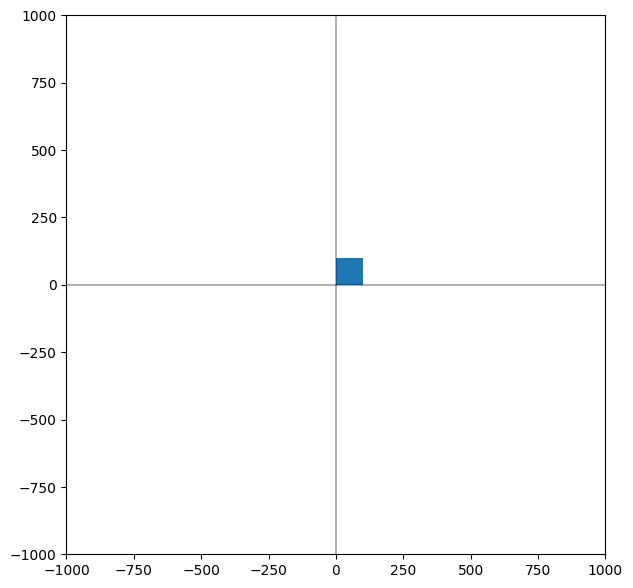

In [58]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [60]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [61]:
# 크기 변환
def scale(p, sx, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 크기 변환 행렬 생성
  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [62]:
# 회전 변환
def rotate(p, theta):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  c = np.cos(theta)
  s = np.sin(theta)

   # 2. 회전 변환 행렬 생성
  m = np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [63]:
# 기울기변환 x축
def shear_x(p, sx):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])
  # 2. x축 기울기 변환 행렬 생성
  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [64]:
# 기울기변환 y축
def shear_y(p, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y축 기울기 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [65]:
# 반전 변환 x축 대칭
def reflect_x(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. x축 반전 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [66]:
# 반전 변환 y축 대칭
def reflect_y(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y축 반전 변환 행렬 생성
  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [67]:
# 반전 변환 원점 대칭
def reflect_origin(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 원점 대칭 반전 변환 행렬 생성
  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [68]:
# 반전 변환 y=x 대칭
def reflect_yx(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y=x 대칭 반전 변환 행렬 생성
  m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [69]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)


  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [70]:
def draw_left_arm(ax, p1, p2, p3, p4):  # 왼쪽 날개축 (우측 배치)
  # 1. 크기 변환: S(8.0, 0.7)
  q1 = scale(p1, 8.0, 0.7)
  q2 = scale(p2, 8.0, 0.7)
  q3 = scale(p3, 8.0, 0.7)
  q4 = scale(p4, 8.0, 0.7)

  # 2. 이동 변환: T(0.0, 70.0)
  u1 = translate(q1, 0.0, 70.0)
  u2 = translate(q2, 0.0, 70.0)
  u3 = translate(q3, 0.0, 70.0)
  u4 = translate(q4, 0.0, 70.0)

  # 3. 기울기 변환: Sh_y(-0.14) - 위쪽 지지대
  u1 = shear_y(u1, -0.14)
  u2 = shear_y(u2, -0.14)
  u3 = shear_y(u3, -0.14)
  u4 = shear_y(u4, -0.14)
  draw_rectangle(ax, u1, u2, u3, u4)

  # 4. 반전 변환(x축): 아래쪽 지지대
  d1 = reflect_x(u1)
  d2 = reflect_x(u2)
  d3 = reflect_x(u3)
  d4 = reflect_x(u4)
  draw_rectangle(ax, d1, d2, d3, d4)

In [71]:
def draw_right_arm(ax, p1, p2, p3, p4):  # 오른쪽 날개축 (좌측 배치)
  q1 = scale(p1, 8.0, 0.7)
  q2 = scale(p2, 8.0, 0.7)
  q3 = scale(p3, 8.0, 0.7)
  q4 = scale(p4, 8.0, 0.7)

  u1 = translate(q1, 0.0, 70.0)
  u2 = translate(q2, 0.0, 70.0)
  u3 = translate(q3, 0.0, 70.0)
  u4 = translate(q4, 0.0, 70.0)

  u1 = shear_y(u1, -0.14)
  u2 = shear_y(u2, -0.14)
  u3 = shear_y(u3, -0.14)
  u4 = shear_y(u4, -0.14)

  # 반전 변환(y축)으로 반대편 이동
  u1 = reflect_y(u1)
  u2 = reflect_y(u2)
  u3 = reflect_y(u3)
  u4 = reflect_y(u4)
  draw_rectangle(ax, u1, u2, u3, u4)

  # 반전 변환(x축)으로 아래쪽 지지대 생성
  d1 = reflect_x(u1)
  d2 = reflect_x(u2)
  d3 = reflect_x(u3)
  d4 = reflect_x(u4)
  draw_rectangle(ax, d1, d2, d3, d4)

In [72]:
def draw_left_wing(ax, p1, p2, p3, p4):  # 왼쪽 날개 (우측 배치)
  # 1. 사각형 높이 조정 이동: T(0.0, -2*LEN) -> y가 [-200, -100]이 되도록 이동 (또는 크기 변환 후 이동)
  q1 = scale(p1, 1.0, 6.0)
  q2 = scale(p2, 1.0, 6.0)
  q3 = scale(p3, 1.0, 6.0)
  q4 = scale(p4, 1.0, 6.0)

  # 2. y축 방향으로 -200 이동하여 y범위를 [-200, 400]으로 맞춤
  u1 = translate(q1, 0.0, -200.0)
  u2 = translate(q2, 0.0, -200.0)
  u3 = translate(q3, 0.0, -200.0)
  u4 = translate(q4, 0.0, -200.0)

  # 3. 기울기 변환: Sh_y(2.0) -> 바깥쪽 변의 y범위가 [0, 600]이 되어 중앙이 비지 않음
  u1 = shear_y(u1, 2.0)
  u2 = shear_y(u2, 2.0)
  u3 = shear_y(u3, 2.0)
  u4 = shear_y(u4, 2.0)

  # 4. 이동 변환: T(750.0, 0.0) - 위쪽 날개
  u1 = translate(u1, 750.0, 0.0)
  u2 = translate(u2, 750.0, 0.0)
  u3 = translate(u3, 750.0, 0.0)
  u4 = translate(u4, 750.0, 0.0)
  draw_rectangle(ax, u1, u2, u3, u4)

  # 5. 반전 변환(x축): 아래쪽 날개
  d1 = reflect_x(u1)
  d2 = reflect_x(u2)
  d3 = reflect_x(u3)
  d4 = reflect_x(u4)
  draw_rectangle(ax, d1, d2, d3, d4)

In [73]:
def draw_right_wing(ax, p1, p2, p3, p4):  # 오른쪽 날개 (좌측 배치)
  q1 = scale(p1, 1.0, 6.0)
  q2 = scale(p2, 1.0, 6.0)
  q3 = scale(p3, 1.0, 6.0)
  q4 = scale(p4, 1.0, 6.0)

  u1 = translate(q1, 0.0, -200.0)
  u2 = translate(q2, 0.0, -200.0)
  u3 = translate(q3, 0.0, -200.0)
  u4 = translate(q4, 0.0, -200.0)

  u1 = shear_y(u1, 2.0)
  u2 = shear_y(u2, 2.0)
  u3 = shear_y(u3, 2.0)
  u4 = shear_y(u4, 2.0)

  u1 = translate(u1, 750.0, 0.0)
  u2 = translate(u2, 750.0, 0.0)
  u3 = translate(u3, 750.0, 0.0)
  u4 = translate(u4, 750.0, 0.0)

  # 반전 변환(y축)으로 반대편 이동
  u1 = reflect_y(u1)
  u2 = reflect_y(u2)
  u3 = reflect_y(u3)
  u4 = reflect_y(u4)
  draw_rectangle(ax, u1, u2, u3, u4)

  # 반전 변환(x축)으로 아래쪽 날개 생성
  d1 = reflect_x(u1)
  d2 = reflect_x(u2)
  d3 = reflect_x(u3)
  d4 = reflect_x(u4)
  draw_rectangle(ax, d1, d2, d3, d4)

In [74]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

  # 2. 왼쪽 날개축 그리기
  draw_left_arm(ax, p1, p2, p3, p4)

  # 3. 왼쪽 날개 그리기
  draw_left_wing(ax, p1, p2, p3, p4)

  # 4. 오른쪽 날개축 그리기
  draw_right_arm(ax, p1, p2, p3, p4)

  # 5. 오른쪽 날개 그리기
  draw_right_wing(ax, p1, p2, p3, p4)

### 3. main

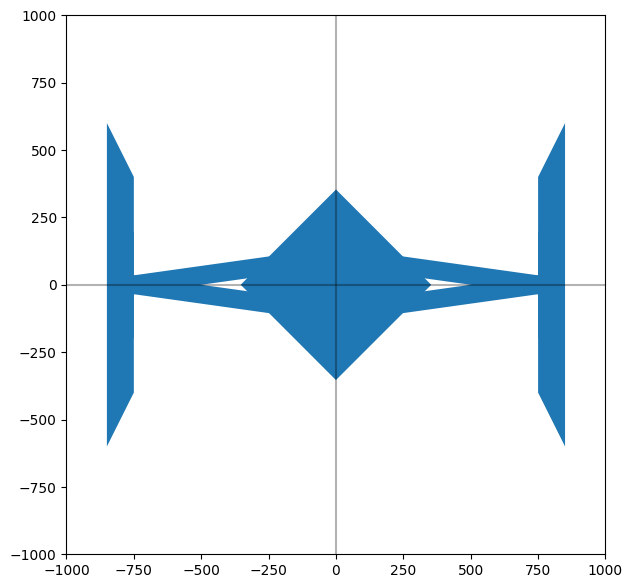

In [76]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()